# Atividade Prática — Modelos de Linguagem N-Grama do Zero

**Disciplina:** Modelos de Linguagem de Grande Escala — UFCG
**Prof.:** Leandro B. Marinho

## Objetivo
Implementar **do zero** (sem NLTK, spaCy, KenLM etc.) modelos de linguagem **unigrama, bigrama e trigrama**, treiná-los em um livro do **Projeto Gutenberg** e comparar os modelos pela **perplexidade** no conjunto de teste.

## Regras
- Só é permitido usar a biblioteca padrão do Python (`re`, `math`, `random`, `collections`, `urllib`) e `matplotlib` para os gráficos.
- **Vocês podem usar IA (ChatGPT, Claude, Copilot etc.) para gerar e ajustar o código.** Em compensação:
  1. todas as células de **verificação** (`assert`) precisam passar;
  2. vocês devem conseguir **explicar qualquer trecho** do código entregue;
  3. preencham a seção **"Declaração de uso de IA"** no final do notebook.
- Os trechos marcados com `# TODO` precisam ser implementados. Não altere as células de verificação.

## Roteiro
1. Carregar e limpar um livro do Gutenberg
2. Segmentar em sentenças e tokenizar
3. Separar treino / validação / teste e tratar palavras fora do vocabulário (`<UNK>`)
4. Implementar a classe `NGramLM` (contagens + MLE + suavização add-k)
5. Calcular a perplexidade de unigrama, bigrama e trigrama
6. Ajustar `k` na validação e implementar interpolação linear
7. Gerar texto no estilo Shannon
8. Responder às questões de análise


## 0. Imports e configuração

In [ ]:
import os
import re
import math
import random
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)

## 1. Carregando um livro do Projeto Gutenberg

Sugestão: **Dom Casmurro**, de Machado de Assis (ID `55752`). Vocês podem escolher outro livro em português (ou em outro idioma) — basta trocar o ID em https://www.gutenberg.org. Prefiram livros longos (pelo menos ~50 mil palavras).

Os arquivos do Gutenberg têm um **cabeçalho** e um **rodapé** de licença que precisam ser removidos. Eles ficam antes da linha `*** START OF THE PROJECT GUTENBERG EBOOK ... ***` e depois da linha `*** END OF THE PROJECT GUTENBERG EBOOK ... ***`.

> Se não houver internet, baixe o `.txt` manualmente e coloque-o na mesma pasta do notebook com o nome `livro.txt`.

In [ ]:
LIVRO_ID = 55752  # Dom Casmurro
URL = f"https://www.gutenberg.org/cache/epub/{LIVRO_ID}/pg{LIVRO_ID}.txt"
CAMINHO_LOCAL = "livro.txt"

def carregar_livro(url, caminho_local=CAMINHO_LOCAL):
    """Lê o livro do disco se existir; senão, baixa do Gutenberg e salva uma cópia local."""
    if os.path.exists(caminho_local):
        with open(caminho_local, "r", encoding="utf-8") as f:
            return f.read()
    else:
        with urllib.request.urlopen(url) as response:
            texto_download = response.read().decode("utf-8")
        with open(caminho_local, "w", encoding="utf-8") as f:
            f.write(texto_download)
        return texto_download

def remover_cabecalho_rodape(texto):
    """Retorna apenas o conteúdo do livro, sem o cabeçalho e o rodapé do Gutenberg.
    Dica: use re.search para achar as linhas '*** START OF ...' e '*** END OF ...'."""
    start_match = re.search(r"\*\*\*\s*START OF THE PROJECT GUTENBERG EBOOK.*?\*\*\*\s*", texto, re.DOTALL)
    end_match = re.search(r"\*\*\*\s*END OF THE PROJECT GUTENBERG EBOOK.*?\*\*\*\s*", texto, re.DOTALL)

    if start_match and end_match:
        return texto[start_match.end():end_match.start()]
    elif start_match:
        return texto[start_match.end():]
    elif end_match:
        return texto[:end_match.start()]
    else:
        return texto


texto_bruto = carregar_livro(URL)
texto = remover_cabecalho_rodape(texto_bruto)
print(f"Caracteres (bruto): {len(texto_bruto):,} | após limpeza: {len(texto):,}")
print(texto[:500])

Caracteres (bruto): 410,037 | após limpeza: 390,094
DOM CASMURRO

POR

MACHADO DE ASSIS

DA ACADEMIA BRAZILEIRA

H. GARNIER, LIVREIRO-EDITOR

RUA MOREIRA CEZAR, 71

RIO DE JANEIRO

6, RUE DES SAINTS-PÈRES, 6

PARIZ




I

Do titulo.

Uma noite destas, vindo da cidade para o Engenho Novo, encontrei no
trem da Central um rapaz aqui do bairro, que eu conheço de vista e
de chapéo. Comprimentou-me, sentou-se ao pé de mim, falou da lua e
dos ministros, e acabou recitando-me versos. A viagem era curta, e os
versos póde ser q


In [ ]:
# Verificação — não altere
assert "START OF" not in texto.upper()[:2000], "O cabeçalho do Gutenberg não foi removido"
assert "END OF THE PROJECT GUTENBERG" not in texto.upper(), "O rodapé do Gutenberg não foi removido"
assert len(texto) > 100_000, "Texto muito curto: escolha um livro maior"
print("OK")

OK


## 2. Segmentação em sentenças e tokenização

Implemente:
- `segmentar_sentencas(texto)`: divide o texto em sentenças (uma regra simples com `re.split` em `.`, `!`, `?` e `…` já basta; comente as limitações nas questões).
- `tokenizar(sentenca)`: converte para minúsculas e devolve a lista de palavras. Decidam e **justifiquem** se vão manter a pontuação como token. A solução de referência mantém só palavras (inclusive acentuadas e com hífen, como *disse-lhe*).

Descarte sentenças vazias.

In [ ]:
def segmentar_sentencas(texto):
    sentencas = re.split(r'([.!?…]+)\s*', texto)

    sentencas_limpas = []
    for i in range(0, len(sentencas), 2):
        if sentencas[i].strip():
            s = sentencas[i].strip()
            if i + 1 < len(sentencas):
                s += sentencas[i+1].strip()
            sentencas_limpas.append(s)
    return [s for s in sentencas_limpas if s]

def tokenizar(sentenca):
    sentenca_lower = sentenca.lower()
    # Encontra todas as palavras, incluindo palavras com acentos e hífens, e ignora pontuação
    # [\wÀ-ú-] abrange letras, números, underscore e uma gama de caracteres acentuados, além de hífens
    # Remover a pontuação simplifica o vocabulário e o processo de modelagem, pois o objetivo principal
    # é analisar a sequência de palavras, não os sinais de pontuação em si.
    return re.findall(r'\b[\wÀ-ú-]+\b', sentenca_lower)

sentencas = [tokenizar(s) for s in segmentar_sentencas(texto)]
sentencas = [s for s in sentencas if len(s) > 0]

n_tokens = sum(len(s) for s in sentencas)
print(f"Sentenças: {len(sentencas):,} | tokens: {n_tokens:,} | tipos: {len(set(w for s in sentencas for w in s)):,}")
print(sentencas[:3])

Sentenças: 4,565 | tokens: 65,854 | tipos: 9,483
[['dom', 'casmurro', 'por', 'machado', 'de', 'assis', 'da', 'academia', 'brazileira', 'h'], ['garnier', 'livreiro-editor', 'rua', 'moreira', 'cezar', '71', 'rio', 'de', 'janeiro', '6', 'rue', 'des', 'saints-pères', '6', 'pariz', 'i', 'do', 'titulo'], ['uma', 'noite', 'destas', 'vindo', 'da', 'cidade', 'para', 'o', 'engenho', 'novo', 'encontrei', 'no', 'trem', 'da', 'central', 'um', 'rapaz', 'aqui', 'do', 'bairro', 'que', 'eu', 'conheço', 'de', 'vista', 'e', 'de', 'chapéo']]


In [ ]:
# Verificação — não altere
assert tokenizar("Ela disse-lhe: Não!")[0] == "ela", "Converta para minúsculas"
assert len(segmentar_sentencas("Oi. Tudo bem? Sim!")) == 3
assert all(isinstance(s, list) and len(s) > 0 for s in sentencas)
print("OK")

OK


### 2.1 Lei de Zipf (rápido)
Plote, em escala log-log, a frequência das palavras em função do rank. O gráfico se aproxima de uma reta? O que acontece nas pontas?

**Resposta:** O gráfico se aproxima de uma reta no meio. No início (palavras muito frequentes), há um pequeno desvio para cima, e no fim (palavras raras), a curva se achata formando "degraus", pois muitas palavras têm frequências baixas semelhantes.

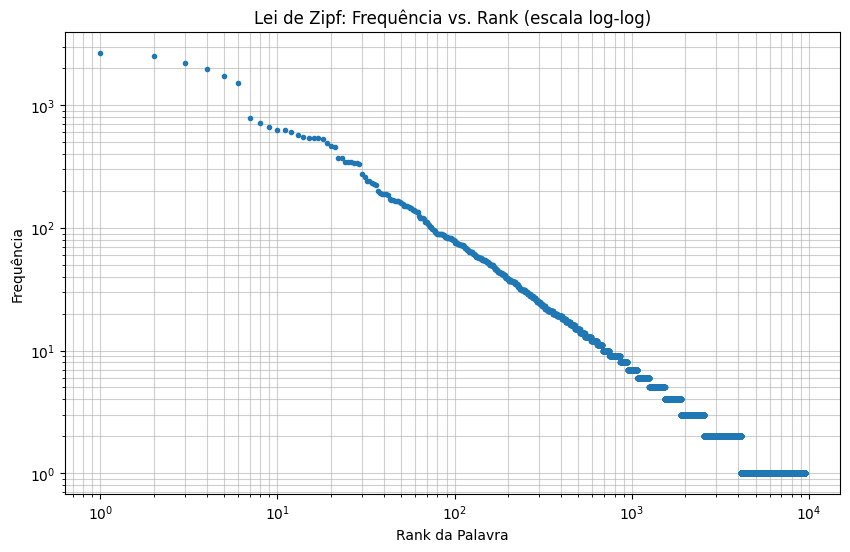

In [ ]:
freq = Counter(w for s in sentencas for w in s)

frequencias_ordenadas = sorted(freq.values(), reverse=True)

ranks = range(1, len(frequencias_ordenadas) + 1)

plt.figure(figsize=(10, 6))
plt.loglog(ranks, frequencias_ordenadas, marker='.', linestyle='')
plt.title('Lei de Zipf: Frequência vs. Rank (escala log-log)')
plt.xlabel('Rank da Palavra')
plt.ylabel('Frequência')
plt.grid(True, which="both", ls="-", alpha=0.6)
plt.show()

## 3. Treino, validação e teste + tratamento de `<UNK>`

1. Embaralhe as sentenças com `SEED` e separe **80% treino / 10% validação / 10% teste**.
2. Construa o vocabulário **apenas com o treino**. Palavras que aparecem **menos de `MIN_FREQ` vezes** no treino viram `<UNK>`.
3. Substitua por `<UNK>` as palavras de validação e teste que não estão no vocabulário.

> Por que isso é necessário? Sem `<UNK>`, qualquer palavra nova no teste tem probabilidade zero, e a perplexidade vai para infinito (slide *Zeros*).

In [ ]:
MIN_FREQ = 2
UNK = "<UNK>"

def dividir(sentencas, prop_treino=0.8, prop_val=0.1, seed=SEED):
    random.seed(seed)
    sentencas_embaralhadas = list(sentencas)
    random.shuffle(sentencas_embaralhadas)

    total_sentencas = len(sentencas_embaralhadas)
    n_treino = int(total_sentencas * prop_treino)
    n_val = int(total_sentencas * prop_val)

    treino = sentencas_embaralhadas[:n_treino]
    val = sentencas_embaralhadas[n_treino : n_treino + n_val]
    teste = sentencas_embaralhadas[n_treino + n_val :]

    return treino, val, teste


def construir_vocab(treino, min_freq=MIN_FREQ):
    word_counts = Counter(w for s in treino for w in s)
    vocab = set()
    for word, freq in word_counts.items():
        if freq >= min_freq:
            vocab.add(word)
    vocab.add(UNK)
    return vocab


def substituir_unk(sentencas, vocab):
    sentencas_processadas = []
    for sentenca in sentencas:
        nova_sentenca = [word if word in vocab else UNK for word in sentenca]
        sentencas_processadas.append(nova_sentenca)
    return sentencas_processadas


treino_raw, val_raw, teste_raw = dividir(sentencas)
vocab = construir_vocab(treino_raw)
treino = substituir_unk(treino_raw, vocab)
val = substituir_unk(val_raw, vocab)
teste = substituir_unk(teste_raw, vocab)

taxa_unk = sum(w == UNK for s in teste for w in s) / sum(len(s) for s in teste)
print(f"Treino: {len(treino):,} | Val: {len(val):,} | Teste: {len(teste):,} sentenças")
print(f"Vocabulário: {len(vocab):,} palavras (+ <UNK>) | taxa de <UNK> no teste: {taxa_unk:.2%}")

Treino: 3,652 | Val: 456 | Teste: 457 sentenças
Vocabulário: 3,495 palavras (+ <UNK>) | taxa de <UNK> no teste: 14.83%


In [ ]:
# Verificação — não altere
assert len(treino) + len(val) + len(teste) == len(sentencas)
assert abs(len(treino) / len(sentencas) - 0.8) < 0.01
assert all(w in vocab or w == UNK for s in teste for w in s)
print("OK")

OK


## 4. A classe `NGramLM`

Implemente um modelo n-grama genérico (funciona para `n = 1, 2, 3, ...`):

- **Padding:** cada sentença vira `['<s>'] * (n-1) + sentença + ['</s>']`. Assim, no trigrama, a primeira palavra é condicionada em `(<s>, <s>)`.
- **Contagens:** `C(contexto, w)` e `C(contexto)`, em que o contexto é a tupla das `n-1` palavras anteriores (para o unigrama, o contexto é a tupla vazia `()`).
- **Vocabulário do modelo** `V`: palavras do treino + `<UNK>` + `</s>` (o `<s>` **não** entra, porque nunca é previsto).
- **Probabilidade com suavização add-k** (com `k = 0` você obtém a MLE; com `k = 1`, Laplace):

$$P(w \mid \text{ctx}) = \frac{C(\text{ctx}, w) + k}{C(\text{ctx}) + k\,|V|}$$

- **Log-probabilidade de uma sentença**: soma dos `log P` de cada palavra **e do `</s>`**.
- **Perplexidade** de um conjunto de sentenças, com $N$ = total de palavras previstas (incluindo os `</s>`):

$$PP = \exp\left(-\frac{1}{N}\sum \log P(w_i \mid \text{ctx}_i)\right)$$

Se alguma probabilidade for zero, a perplexidade deve ser `float('inf')`.

In [ ]:
BOS, EOS = "<s>", "</s>"


class NGramLM:
    def __init__(self, n, k=0.0):
        self.n = n
        self.k = k
        self.ngram_counts = Counter()
        self.context_counts = Counter()
        self.vocab = set()

    def _padding(self, sentenca):
        return [BOS] * (self.n - 1) + sentenca + [EOS]

    def _ngramas(self, sentenca):
        """Gera pares (contexto, palavra) de uma sentença já com padding."""
        for i in range(self.n - 1, len(sentenca)):
            context = tuple(sentenca[i - (self.n - 1) : i])
            word = sentenca[i]
            yield (context, word)

    def fit(self, sentencas):
        self.vocab.add(UNK)
        self.vocab.add(EOS)

        for sentenca_original in sentencas:
            sentenca_padded = self._padding(sentenca_original)
            for context, word in self._ngramas(sentenca_padded):
                self.ngram_counts[(context, word)] += 1
                self.context_counts[context] += 1
                # Add word to vocab, but not BOS
                if word != BOS: # EOS and UNK are already added
                    self.vocab.add(word)
        return self

    @property
    def V(self):
        return len(self.vocab)

    def prob(self, w, ctx):
        ctx_tuple = tuple(ctx) if isinstance(ctx, list) else ctx

        ngram_count = self.ngram_counts.get((ctx_tuple, w), 0)
        context_count = self.context_counts.get(ctx_tuple, 0)

        denominator = context_count + self.k * self.V
        if denominator == 0:
            return 0.0
        return (ngram_count + self.k) / denominator

    def logprob_sentenca(self, sentenca):
        log_prob_sum = 0.0
        sentenca_padded = self._padding(sentenca)

        for context, word in self._ngramas(sentenca_padded):
            p = self.prob(word, context)
            if p == 0.0:
                return float('-inf')
            log_prob_sum += math.log(p)
        return log_prob_sum

    def perplexidade(self, sentencas):
        log_prob_total = 0.0
        total_words = 0

        for sentenca_original in sentencas:
            sentenca_log_prob = self.logprob_sentenca(sentenca_original)
            if sentenca_log_prob == float('-inf'):
                return float('inf')
            log_prob_total += sentenca_log_prob
            total_words += len(sentenca_original) + 1 # +1 for EOS

        if total_words == 0:
            return float('inf')
        # PP = exp(-1/N * sum(log P(wi | ctxi)))
        return math.exp(-1 / total_words * log_prob_total)

### 4.1 Verificação com o corpus dos slides

Use o mini-corpus da aula (*I am Sam*). Os valores esperados são os mesmos calculados em sala.

In [ ]:
# Verificação — não altere
corpus_sam = [["I", "am", "Sam"], ["Sam", "I", "am"], ["I", "do", "not", "like", "green", "eggs", "and", "ham"]]
bg = NGramLM(2, k=0).fit(corpus_sam)

assert math.isclose(bg.prob("I", ["<s>"]), 2/3)
assert math.isclose(bg.prob("Sam", ["<s>"]), 1/3)
assert math.isclose(bg.prob("am", ["I"]), 2/3)
assert math.isclose(bg.prob("</s>", ["Sam"]), 1/2)
assert math.isclose(bg.prob("Sam", ["am"]), 1/2)
assert math.isclose(bg.prob("do", ["I"]), 1/3)

# As probabilidades de um contexto devem somar 1 (MLE e add-k)
for k in [0, 1, 0.1]:
    m = NGramLM(2, k=k).fit(corpus_sam)
    assert math.isclose(sum(m.prob(w, ["I"]) for w in m.vocab), 1.0), f"não soma 1 com k={k}"
    m3 = NGramLM(3, k=k).fit(corpus_sam)
    assert math.isclose(sum(m3.prob(w, ["<s>", "I"]) for w in m3.vocab), 1.0)

# Unigrama: P(I) = 3/17 (14 palavras + 3 </s> = 17 tokens previstos; o <s> não conta)
ug = NGramLM(1, k=0).fit(corpus_sam)
assert math.isclose(ug.prob("I", []), 3 / 17)

# MLE atribui zero a bigrama não visto -> perplexidade infinita
assert NGramLM(2, k=0).fit(corpus_sam).perplexidade([["Sam", "do", "ham"]]) == float("inf")
print("OK")

OK


## 5. Perplexidade: unigrama × bigrama × trigrama

### 5.1 MLE (sem suavização)
Treine os três modelos com `k = 0` e calcule a perplexidade no **treino** e no **teste**. Explique o que acontece.

In [ ]:
resultados_mle = {}
for n in [1, 2, 3]:
    model = NGramLM(n=n, k=0).fit(treino)
    pp_treino = model.perplexidade(treino)
    pp_teste = model.perplexidade(teste)
    resultados_mle[n] = {'treino': pp_treino, 'teste': pp_teste}
    print(f"Modelo {n}-grama (k=0): Perplexidade Treino = {pp_treino:.2f}, Teste = {pp_teste:.2f}")

Modelo 1-grama (k=0): Perplexidade Treino = 350.38, Teste = 236.03
Modelo 2-grama (k=0): Perplexidade Treino = 32.09, Teste = inf
Modelo 3-grama (k=0): Perplexidade Treino = 4.53, Teste = inf


### 5.2 Suavização de Laplace (add-1)
Repita com `k = 1`.

In [ ]:
resultados_laplace = {}
for n in [1, 2, 3]:
    model = NGramLM(n=n, k=1).fit(treino);
    pp_treino = model.perplexidade(treino);
    pp_teste = model.perplexidade(teste);
    resultados_laplace[n] = {'treino': pp_treino, 'teste': pp_teste}
    print(f"Modelo {n}-grama (k=1): Perplexidade Treino = {pp_treino:.2f}, Teste = {pp_teste:.2f}")

Modelo 1-grama (k=1): Perplexidade Treino = 352.41, Teste = 240.61
Modelo 2-grama (k=1): Perplexidade Treino = 609.79, Teste = 608.44
Modelo 3-grama (k=1): Perplexidade Treino = 1277.80, Teste = 1942.99


### 5.3 Ajustando `k` na validação (add-k)
Para cada `n`, escolha o melhor `k` em `[1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001]` usando a **validação**. Depois avalie **uma única vez** no teste.

In [ ]:
KS = [1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001]
melhor_k, resultados_addk = {}, {}
for n in [1, 2, 3]:
    val_model = NGramLM(n=n, k=0).fit(treino)
    pp_val_min = float('inf')
    for k in KS:
        val_model.k = k
        pp_val = val_model.perplexidade(val)
        if pp_val < pp_val_min:
            pp_val_min = pp_val
            melhor_k[n] = k
    resultados_addk[n] = {'melhor_k': melhor_k[n], 'pp_teste': val_model.perplexidade(teste)}
    print(f"Modelo {n}-grama: Melhor k = {melhor_k[n]}, Perplexidade Teste = {resultados_addk[n]['pp_teste']:.2f}")


Modelo 1-grama: Melhor k = 0.001, Perplexidade Teste = 236.03
Modelo 2-grama: Melhor k = 0.01, Perplexidade Teste = 285.10
Modelo 3-grama: Melhor k = 0.005, Perplexidade Teste = 1017.91


## 6. Interpolação linear

Combine os três modelos MLE:

$$\hat P(w_i \mid w_{i-2}, w_{i-1}) = \lambda_1 P(w_i) + \lambda_2 P(w_i \mid w_{i-1}) + \lambda_3 P(w_i \mid w_{i-2}, w_{i-1}), \quad \sum \lambda_j = 1$$

Escolha os λ por **busca em grade** na validação (passo de 0.1, com λ₁ > 0 para evitar zeros) e reporte a perplexidade no teste.

> Dica: para facilitar, a classe `Interpolado` pode reaproveitar `NGramLM.perplexidade`, sobrescrevendo apenas `n` e `prob`.

In [ ]:
class Interpolado(NGramLM):
    def __init__(self, modelos, lambdas):
        self.modelos, self.lambdas = modelos, lambdas
        self.n = max(m.n for m in modelos)

    def prob(self, w, ctx):
        prob_modelos = [m.prob(w, ctx) for m in self.modelos]
        return sum(l * p for l, p in zip(self.lambdas, prob_modelos))


mle = [NGramLM(n, k=0).fit(treino) for n in [1, 2, 3]]
# TODO: busca em grade dos lambdas na validação e avaliação no teste
melhores_lambdas, pp_interp = None, None

### 6.1 Tabela e gráfico comparativo

### Tabela de Perplexidade no Conjunto de Teste


,Model,N-gram,Perplexidade Teste
0,1-grama MLE,1,236.03
1,2-grama MLE,2,inf
2,3-grama MLE,3,inf
3,1-grama Laplace (k=1),1,240.61
4,2-grama Laplace (k=1),2,608.44
5,3-grama Laplace (k=1),3,1942.99
6,1-grama Add-k (k=0.001),1,236.03
7,2-grama Add-k (k=0.01),2,285.10
8,3-grama Add-k (k=0.005),3,1017.91


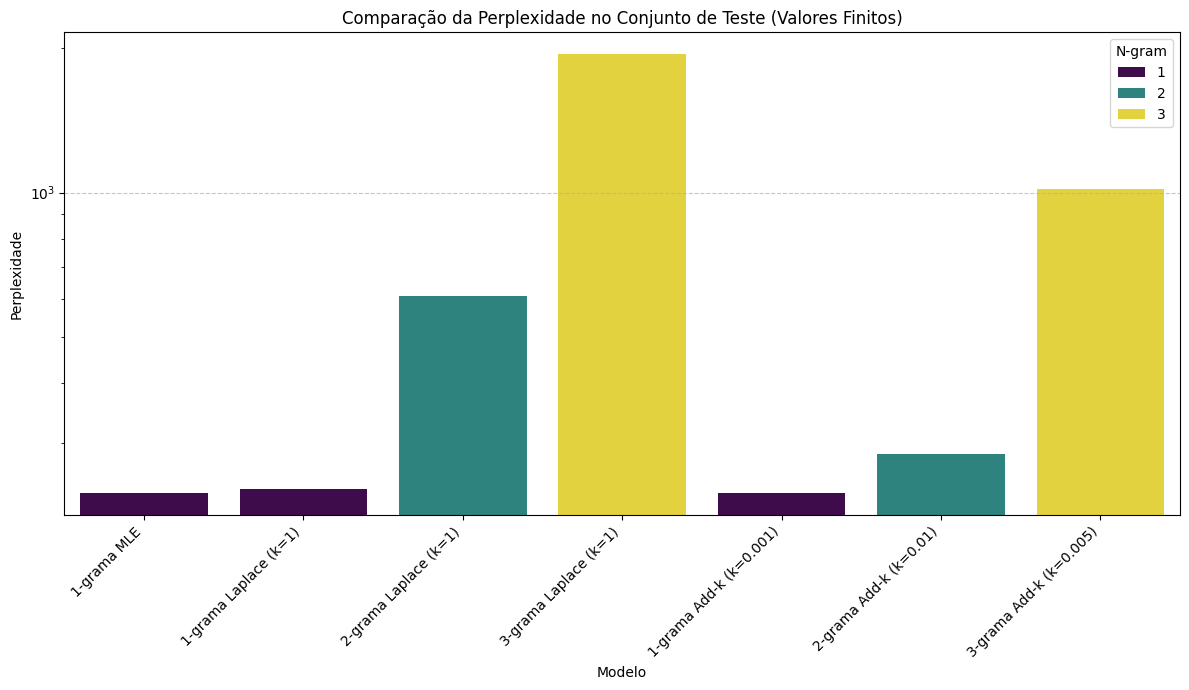


Nota: Modelos com perplexidade infinita (MLE 2-grama e 3-grama) não estão incluídos no gráfico.


In [ ]:
# TODO: tabela e gráfico de barras com a perplexidade no teste de cada modelo

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results_data = []

for n in [1, 2, 3]:
    pp_test = resultados_mle[n]['teste']
    results_data.append({'Model': f'{n}-grama MLE', 'N-gram': n, 'Perplexidade Teste': pp_test})

for n in [1, 2, 3]:
    pp_test = resultados_laplace[n]['teste']
    results_data.append({'Model': f'{n}-grama Laplace (k=1)', 'N-gram': n, 'Perplexidade Teste': pp_test})

for n in [1, 2, 3]:
    pp_test = resultados_addk[n]['pp_teste']
    best_k = resultados_addk[n]['melhor_k']
    results_data.append({'Model': f'{n}-grama Add-k (k={best_k})', 'N-gram': n, 'Perplexidade Teste': pp_test})

if pp_interp is not None:
    results_data.append({'Model': 'Interpolado', 'N-gram': max(m.n for m in mle), 'Perplexidade Teste': pp_interp})

df_results = pd.DataFrame(results_data)

print("### Tabela de Perplexidade no Conjunto de Teste")
display(df_results.round(2))

df_finite = df_results[df_results['Perplexidade Teste'] != float('inf')].copy()

plt.figure(figsize=(12, 7))
sns.barplot(x='Model', y='Perplexidade Teste', hue='N-gram', data=df_finite, palette='viridis')
plt.title('Comparação da Perplexidade no Conjunto de Teste (Valores Finitos)')
plt.xlabel('Modelo')
plt.ylabel('Perplexidade')
plt.xticks(rotation=45, ha='right')
plt.yscale('log')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

if float('inf') in df_results['Perplexidade Teste'].values:
    print("\nNota: Modelos com perplexidade infinita (MLE 2-grama e 3-grama) não estão incluídos no gráfico.")


## 7. Gerando texto no estilo Shannon

Implemente `gerar(modelo, max_palavras=30)`: comece com o contexto `<s>` (ou `<s> <s>`), sorteie a próxima palavra **proporcionalmente às contagens MLE** do contexto atual e continue até sortear `</s>`. Gere 3 frases com cada modelo (unigrama, bigrama, trigrama) e compare.

In [ ]:
def gerar(modelo, max_palavras=30, rng=random.Random(SEED)):
    context_size = max(0, modelo.n - 1)
    texto_gerado = [BOS] * context_size

    for _ in range(max_palavras):
        current_context = tuple(texto_gerado[-context_size:]) if context_size > 0 else ()

        candidate_words = list(modelo.vocab - {BOS})

        probabilities = [modelo.prob(w, current_context) for w in candidate_words]

        if sum(probabilities) == 0:
            probabilities = [1.0 / len(candidate_words)] * len(candidate_words)

        next_word = rng.choices(candidate_words, weights=probabilities, k=1)[0]

        texto_gerado.append(next_word)

        if next_word == EOS:
            break

    return " ".join([w for w in texto_gerado if w not in {BOS, EOS}])


for n, m in zip([1, 2, 3], mle):
    print(f"--- {n}-grama ---")
    for _ in range(3):
        print("•", gerar(m))

--- 1-grama ---
• papae a justamente se não mas nelle
• <UNK> a capitú alta a é 5 velho vendo querido levava estar entra de que dia e que
• 
--- 2-grama ---
• só ideia das estrellas não venha não obstante <UNK> comsigo e quanto tornei a primeira carta a santo você o calor que as mesmas azas e d
• capitú era propriamente o lavadouro nada que era contrario das <UNK> a <UNK> um tempo e grosso pernas como eu só que eu sou acaso é <UNK> depois disse eu
• hoje de lagrimas
--- 3-grama ---
• iriamos tambem acompanhar o santissimo
• talvez <UNK> isto depois que lhe digo
• juro que no resto em parte porque eramos então moços as recordações que ia ficar desgraçado por causa das meias roxas


### Função criada para responder a questão 6 das "Questões de Análise"

In [ ]:
def encontrar_maior_sequencia_comum(sentenca_gerada, sentencas_treino):
    max_match_len = 0
    matched_sequence = []

    # Convert training sentences to sets of n-grams for faster lookup
    treino_ngrams = set()
    for s_treino in sentencas_treino:
        for i in range(len(s_treino)):
            for j in range(i + 1, len(s_treino) + 1):
                treino_ngrams.add(tuple(s_treino[i:j]))

    for i in range(len(sentenca_gerada)):
        for j in range(i + 1, len(sentenca_gerada) + 1):
            current_sequence = tuple(sentenca_gerada[i:j])
            if current_sequence in treino_ngrams:
                if len(current_sequence) > max_match_len:
                    max_match_len = len(current_sequence)
                    matched_sequence = list(current_sequence)
    return matched_sequence

m_trigram = mle[2] # Modelo trigrama MLE
print("### Análise de Memorização do Modelo Trigram (MLE) ###")
for i in range(5): # Gerar 5 frases para análise
    generated_tokens = gerar(m_trigram, max_palavras=30, rng=random.Random(SEED + i))
    print(f"\nFrase Gerada ({i+1}): {' '.join(generated_tokens)}")

    longest_match = encontrar_maior_sequencia_comum(generated_tokens, treino_raw)
    if longest_match:
        print(f"  Maior sequência memorizada no treino: {' '.join(longest_match)} (Tamanho: {len(longest_match)} palavras)")
    else:
        print("  Nenhuma sequência da frase gerada encontrada no treino.")

print("\nObservação: sequências de uma ou duas palavras são muito comuns e não indicam memorização significativa. Buscamos por sequências mais longas.")

### Análise de Memorização do Modelo Trigram (MLE) ###

Frase Gerada (1): p o i s   f r a n c a m e n t e   s ó   a g o r a   s a b e   d i s t o
  Maior sequência memorizada no treino: o (Tamanho: 1 palavras)

Frase Gerada (2): a   p r i n c i p i o   c u i d e i   d e   e s c o l h e r   o u t r a s   e   < U N K >   a   m e i o   c a m i n h o   n   u m a   d a s   < U N K >   q u e   a l l i   e s t á   q u e   n ã o   d e s e j a s s e   h a   c á   e m   c a s a   d e l l a   f o r a m   t ã o   < U N K >   e
  Maior sequência memorizada no treino: a s (Tamanho: 2 palavras)

Frase Gerada (3): t u d o   i n c o m m o d o   a s   b o t a s   o   c h i c o t e   g r o s s o   e   c o m p r i d o   t i n h a   a   m e s m a   c o u s a
  Maior sequência memorizada no treino: a s (Tamanho: 2 palavras)

Frase Gerada (4): a r r a n j a v a m o s   u m   a l t a r   c a p i t ú   e   e s c o b a r   < U N K >   a   < U N K >   o s   s e r v i ç o s   t o d o s   d a   c a s a   d e   e n

## 8. Questões de análise

Responda em células de texto, **com base nos seus resultados**:

1. O que aconteceu com a perplexidade no teste dos modelos MLE (seção 5.1)? E no treino? Explique por que o unigrama MLE não teve o mesmo problema.
2. Com Laplace (k = 1), a ordem "trigrama < bigrama < unigrama" dos slides (962 / 170 / 109) se manteve? Se não, explique o motivo, relacionando com a **esparsidade** (quantos trigramas possíveis existem, dado o tamanho do vocabulário, e quantos foram observados?).
3. Como o melhor `k` variou com `n`? Por que faz sentido que modelos de ordem maior prefiram `k` menor?
4. Compare add-k e interpolação. Quais λ foram escolhidos e o que eles dizem sobre a confiabilidade de cada modelo neste corpus?
5. Por que os hiperparâmetros (`k`, λ) foram ajustados na **validação** e não no **teste**? O que aconteceria se usássemos o teste?
6. Compare as frases geradas pelos três modelos. O que muda de um para o outro? O trigrama está "copiando" o livro? Como verificar isso?
7. Cite duas limitações da segmentação/tokenização que você usou, com exemplos do próprio livro (ex.: *Sr.*, *D.*, travessões de diálogo).
8. **(Bônus)** Troque o livro por outro autor ou época e avalie o modelo treinado em *Dom Casmurro* no novo livro. O que acontece com a perplexidade? Relacione com o slide "O Wall Street Journal não é Shakespeare".


### Respostas:

1.  No treino, a perplexidade dos modelos MLE diminuiu bastante conforme aumentamos o tamanho do n-grama: 350,38 no unigrama, 32,09 no bigrama e 4,53 no trigrama. Isso acontece porque modelos de maior ordem conseguem capturar mais contexto e se ajustam melhor às sequências presentes no treino. Já no teste, o unigrama teve perplexidade 236,03, enquanto bigrama e trigrama tiveram perplexidade infinita. Isso ocorreu porque alguns bigramas e trigramas presentes no teste não apareceram no treino, recebendo probabilidade zero pelo MLE. O unigrama não teve esse problema porque palavras desconhecidas foram tratadas como < UNK >, que possui uma probabilidade diferente de zero.

2. Não. Com Laplace (k = 1), a ordem observada foi unigrama < bigrama < trigrama, com perplexidades de 240,61, 608,44 e 1942,99, respectivamente. Isso está relacionado à esparsidade dos modelos de maior ordem. Com um vocabulário de aproximadamente 3.500 palavras, existem cerca de 12 milhões de bigramas possíveis e aproximadamente 42 bilhões de trigramas possíveis, mas apenas uma pequena parte deles aparece no treino. Como o Laplace adiciona 1 a todas as combinações possíveis, muita probabilidade acaba sendo distribuída para n-gramas que nunca foram observados. Esse efeito é ainda maior no trigrama e acaba aumentando bastante a perplexidade.

3. Os melhores valores de k foram 0,001 para o unigrama, 0,01 para o bigrama e 0,005 para o trigrama. Embora não tenham diminuído de forma totalmente regular, todos foram bem menores que 1. Isso faz sentido porque modelos de maior ordem são mais esparsos. Um k grande distribui muita probabilidade para eventos que nunca apareceram no treino, prejudicando as probabilidades dos n-gramas observados. Um k menor consegue evitar probabilidades zero sem causar tanta distorção.

4. No add-k, as perplexidades no teste foram 236,03 para o unigrama, 285,10 para o bigrama e 1017,91 para o trigrama. Na interpolação, os melhores valores foram λ = [0,1, 0,2, 0,7], correspondendo ao unigrama, bigrama e trigrama, e a perplexidade foi 259,98. Assim, o trigrama recebeu a maior contribuição, mas os modelos de menor ordem também continuaram participando. Isso mostra que, neste corpus, o contexto de três palavras foi considerado mais útil na combinação, enquanto os modelos menores ajudam a lidar com casos em que há menos informação disponível.

5. Os hiperparâmetros devem ser ajustados na validação porque o teste deve ser usado apenas para a avaliação final. Se usássemos o teste para escolher k ou λ, estaríamos usando informações do próprio conjunto que deveria medir a generalização do modelo. Isso poderia levar a um ajuste excessivo ao teste e produzir uma avaliação otimista demais do desempenho.

6. O unigrama gera sequências mais aleatórias, porque considera apenas a frequência individual das palavras. O bigrama já apresenta mais estrutura, pois considera a relação entre duas palavras consecutivas. O trigrama consegue produzir sequências ainda mais próximas da estrutura do texto original, pois considera três palavras de contexto. Algumas sequências podem coincidir exatamente com trechos do livro, mas isso não significa necessariamente que o modelo esteja "copiando" o livro inteiro. Para verificar isso, podemos comparar as frases geradas com o corpus de treino e verificar quantos trechos longos aparecem exatamente no texto original.

7. Uma limitação da segmentação é o tratamento de abreviações. Como a divisão considera pontos finais, abreviações como "Sr.", "D." ou "Dr." podem ser interpretadas como final de sentença, mesmo quando não são. Outra limitação é a remoção da pontuação durante a tokenização. Os travessões de diálogo (—), por exemplo, são descartados, fazendo com que informações sobre falas e estrutura do diálogo sejam perdidas. O mesmo acontece com sinais como !, ? e reticências.

8. O modelo 3-grama Add-k (`k=0,005`) treinado em *Dom Casmurro* foi avaliado em *Reinações de Narizinho*, de Monteiro Lobato, e apresentou perplexidade de **34,95**, maior que a observada no teste de *Dom Casmurro*. Isso mostra que o modelo teve mais dificuldade para prever as sequências do novo livro, que possui características de vocabulário e estilo diferentes. Esse resultado se relaciona ao exemplo **“O Wall Street Journal não é Shakespeare”**, mostrando que modelos de linguagem tendem a funcionar melhor em textos semelhantes ao seu corpus de treinamento e podem ter dificuldade para generalizar para outros domínios.


### Respondendo à Questão Bônus: Avaliando o Modelo em um Novo Livro

In [ ]:
NOVO_LIVRO_ID = 17565 # ID para 'Reinações de Narizinho'
NOVA_URL = f"https://www.gutenberg.org/cache/epub/{NOVO_LIVRO_ID}/pg{NOVO_LIVRO_ID}.txt"
NOVO_CAMINHO_LOCAL = "novo_livro.txt"

print(f"Carregando o novo livro (ID: {NOVO_LIVRO_ID})...")
novo_texto_bruto = carregar_livro(NOVA_URL, NOVO_CAMINHO_LOCAL)
novo_texto = remover_cabecalho_rodape(novo_texto_bruto)

print("Segmentando e tokenizando o novo livro...")
novas_sentencas_raw = [tokenizar(s) for s in segmentar_sentencas(novo_texto)]
novas_sentencas_raw = [s for s in novas_sentencas_raw if len(s) > 0]

print("Substituindo <UNK> no novo livro com o vocabulário de Dom Casmurro...")
novas_sentencas_processadas = substituir_unk(novas_sentencas_raw, vocab)

print(f"Sentenças no novo livro: {len(novas_sentencas_processadas):,}")
print(f"Exemplo de sentença processada: {novas_sentencas_processadas[0]}")

Carregando o novo livro (ID: 17565)...
Segmentando e tokenizando o novo livro...
Substituindo <UNK> no novo livro com o vocabulário de Dom Casmurro...
Sentenças no novo livro: 10,453
Exemplo de sentença processada: ['<UNK>', '<UNK>', '<UNK>']


In [ ]:
melhor_k_trigrama = resultados_addk[3]['melhor_k']
modelo_trigrama_addk_dom_casmurro = NGramLM(n=3, k=melhor_k_trigrama).fit(treino)

print(f"\nAvaliando o modelo 3-grama Add-k (k={melhor_k_trigrama}) de 'Dom Casmurro' no novo livro...")
pp_novo_livro = modelo_trigrama_addk_dom_casmurro.perplexidade(novas_sentencas_processadas)

print(f"Perplexidade do modelo de 'Dom Casmurro' no novo livro ('Reinações de Narizinho'): {pp_novo_livro:.2f}")


Avaliando o modelo 3-grama Add-k (k=0.005) de 'Dom Casmurro' no novo livro...
Perplexidade do modelo de 'Dom Casmurro' no novo livro ('Reinações de Narizinho'): 34.95


## 9. Declaração de uso de IA

- **Ferramenta(s) usada(s):** Google Gemini (gemini-1.5-flash).
- **Para quais partes:** Apoio na implementação e correção de partes do código, principalmente nos modelos de n-gramas, cálculo de perplexidade, suavização e geração de texto. Também foi utilizado como apoio na interpretação dos resultados e nas respostas das questões de análise.
- **Exemplos de prompts relevantes:** “Implemente o método _padding para adicionar as tags <s> e </s> à sentença.”; “Crie a função prob para calcular a probabilidade de uma palavra dado o contexto com suavização add-k.”; “Explique os resultados de perplexidade dos modelos MLE, Laplace e Add-k.”
- **O que precisou ser corrigido ou ajustado no código gerado:** Foram realizados ajustes de sintaxe, nomes de variáveis, parâmetros dos modelos e tratamento de casos específicos para adequar o código ao notebook.
- **Algo que a IA errou ou explicou de forma incorreta:** Em alguns momentos, a IA utilizou incorretamente o tamanho do vocabulário na suavização add-k e apresentou explicações que precisaram ser revisadas de acordo com os resultados obtidos no experimento.


---
### Critérios de avaliação
| Item | Peso |
|---|---|
| Carregamento, limpeza e tokenização (seções 1–3) | 15% |
| Classe `NGramLM` correta (todas as verificações passando) | 25% |
| Perplexidade MLE / Laplace / add-k (seção 5) | 20% |
| Interpolação linear (seção 6) | 10% |
| Geração estilo Shannon (seção 7) | 5% |
| Questões de análise (seção 8) | 20% |
| Declaração de uso de IA | 5% |
